In [ ]:
# Data handling
import os
import json
import warnings
import joblib
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

# Dataset splitting
from sklearn.model_selection import train_test_split, GroupShuffleSplit

# ML models
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score
)

# Model persistence
from pathlib import Path

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
df = pd.read_csv('/content/agro_environmental_dataset.csv')
df

,location_id,soil_type,bulk_density,organic_matter_pct,cation_exchange_capacity,salinity_ec,buffering_capacity,soil_moisture_pct,moisture_limit_dry,moisture_limit_wet,...,soil_ph,ph_stress_flag,nitrogen_ppm,phosphorus_ppm,potassium_ppm,nutrient_balance,plant_category,suitability_score,stress_level,failure_flag
0,L00000,Clayey,1.1,4.0,30,0.5,0.9,5.17,25,52,...,6.48,0,100.1,50.8,121.3,excessive,vegetable,0.677,1,0
1,L00001,Alluvial,1.3,3.8,20,0.4,0.7,26.28,16,45,...,6.43,0,133.8,54.9,151.6,optimal,vegetable,0.871,0,0
2,L00002,Chalky,1.5,2.0,8,0.3,0.4,44.90,12,35,...,5.01,1,84.5,83.6,83.6,deficient,vegetable,0.000,2,1
3,L00003,Silty,1.4,3.0,18,0.4,0.6,27.05,18,42,...,5.41,1,168.2,30.5,220.0,deficient,cereal,0.510,1,0
4,L00004,Loamy,1.3,3.5,15,0.3,0.7,36.56,15,40,...,6.73,0,98.9,63.4,88.9,optimal,vegetable,1.000,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
543205,L543205,Chalky,1.5,2.0,8,0.3,0.4,45.39,12,35,...,7.32,0,86.9,31.1,124.7,deficient,cereal,0.188,2,1
543206,L543206,Peaty,0.7,18.0,40,0.2,0.8,26.78,30,65,...,5.67,0,84.4,12.2,101.1,deficient,cereal,0.458,1,0
543207,L543207,Clayey,1.1,4.0,30,0.5,0.9,25.68,25,52,...,6.28,0,77.4,40.5,49.7,optimal,legume,0.939,0,0
543208,L543208,Alluvial,1.3,3.8,20,0.4,0.7,38.95,16,45,...,6.24,0,76.7,76.7,84.3,optimal,cereal,0.994,0,0


In [ ]:
# Display the first 5 rows
df.head()

,location_id,soil_type,bulk_density,organic_matter_pct,cation_exchange_capacity,salinity_ec,buffering_capacity,soil_moisture_pct,moisture_limit_dry,moisture_limit_wet,...,soil_ph,ph_stress_flag,nitrogen_ppm,phosphorus_ppm,potassium_ppm,nutrient_balance,plant_category,suitability_score,stress_level,failure_flag
0,L00000,Clayey,1.1,4.0,30,0.5,0.9,5.17,25,52,...,6.48,0,100.1,50.8,121.3,excessive,vegetable,0.677,1,0
1,L00001,Alluvial,1.3,3.8,20,0.4,0.7,26.28,16,45,...,6.43,0,133.8,54.9,151.6,optimal,vegetable,0.871,0,0
2,L00002,Chalky,1.5,2.0,8,0.3,0.4,44.90,12,35,...,5.01,1,84.5,83.6,83.6,deficient,vegetable,0.000,2,1
3,L00003,Silty,1.4,3.0,18,0.4,0.6,27.05,18,42,...,5.41,1,168.2,30.5,220.0,deficient,cereal,0.510,1,0
4,L00004,Loamy,1.3,3.5,15,0.3,0.7,36.56,15,40,...,6.73,0,98.9,63.4,88.9,optimal,vegetable,1.000,0,0


In [ ]:
# Number of rows and columns
print("Dataset shape:", df.shape)

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Data types and non-null counts
print("\nDataset information:")
df.info()

Dataset shape: (543210, 25)

Column names:
['location_id', 'soil_type', 'bulk_density', 'organic_matter_pct', 'cation_exchange_capacity', 'salinity_ec', 'buffering_capacity', 'soil_moisture_pct', 'moisture_limit_dry', 'moisture_limit_wet', 'moisture_regime', 'soil_temp_c', 'air_temp_c', 'thermal_regime', 'light_intensity_par', 'soil_ph', 'ph_stress_flag', 'nitrogen_ppm', 'phosphorus_ppm', 'potassium_ppm', 'nutrient_balance', 'plant_category', 'suitability_score', 'stress_level', 'failure_flag']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 543210 entries, 0 to 543209
Data columns (total 25 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   location_id               543210 non-null  object 
 1   soil_type                 543210 non-null  object 
 2   bulk_density              543210 non-null  float64
 3   organic_matter_pct        543210 non-null  float64
 4   cation_exchange_capacity  

In [ ]:
# Count each stress level
print(df["stress_level"].value_counts().sort_index())

# Calculate percentage of each class
print((df["stress_level"].value_counts(normalize=True).sort_index() * 100).round(2))

stress_level
0    175267
1    239013
2    128930
Name: count, dtype: int64
stress_level
0    32.27
1    44.00
2    23.73
Name: proportion, dtype: float64


In [ ]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check unique values in categorical columns
categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    print(f"{col}: {df[col].nunique()} unique values")

Duplicate rows: 0
location_id: 543210 unique values
soil_type: 9 unique values
moisture_regime: 3 unique values
thermal_regime: 3 unique values
nutrient_balance: 3 unique values
plant_category: 3 unique values


In [ ]:
# Summary statistics for numerical columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
bulk_density,543210.0,1.319365,0.243070,0.7,1.300,1.300,1.500,1.6
organic_matter_pct,543210.0,4.000303,4.278072,1.2,1.800,3.500,3.800,18.0
cation_exchange_capacity,543210.0,17.212248,10.367455,5.0,8.000,15.000,20.000,40.0
salinity_ec,543210.0,0.673847,0.986025,0.2,0.300,0.400,0.500,4.0
buffering_capacity,543210.0,0.610260,0.198579,0.3,0.400,0.700,0.700,0.9
soil_moisture_pct,543210.0,34.977238,11.927853,5.0,26.870,34.970,43.070,70.0
moisture_limit_dry,543210.0,16.945798,6.615230,8.0,12.000,16.000,22.000,30.0
moisture_limit_wet,543210.0,42.566326,9.681918,28.0,38.000,42.000,45.000,65.0
soil_temp_c,543210.0,25.003662,4.991071,10.0,21.600,25.000,28.400,40.0
air_temp_c,543210.0,28.007091,5.379043,7.0,24.400,28.000,31.600,49.6


In [ ]:
# Check how stress level relates to other target-like columns
print(pd.crosstab(df["stress_level"], df["ph_stress_flag"]))
print("\nStress level vs failure flag:")
print(pd.crosstab(df["stress_level"], df["failure_flag"]))

print("\nSuitability score by stress level:")
print(df.groupby("stress_level")["suitability_score"].describe())

ph_stress_flag       0      1
stress_level                 
0               171345   3922
1               193722  45291
2                66015  62915

Stress level vs failure flag:
failure_flag       0      1
stress_level               
0             175140    127
1             233520   5493
2              46470  82460

Suitability score by stress level:
                 count      mean       std   min      25%    50%    75%   max
stress_level                                                                 
0             175267.0  0.882585  0.093849  0.75  0.78800  0.878  0.989  1.00
1             239013.0  0.595437  0.098379  0.45  0.50400  0.577  0.697  0.75
2             128930.0  0.280531  0.125443  0.00  0.20325  0.279  0.401  0.45


In [ ]:
# Create a copy of the original dataset
df_clean = df.copy()

# Standardize column names
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

# Replace empty strings with missing values
df_clean = df_clean.replace(r"^\s*$", pd.NA, regex=True)

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Remove rows where the target is missing
df_clean = df_clean.dropna(subset=["stress_level"])

# Ensure target is numeric
df_clean["stress_level"] = pd.to_numeric(
    df_clean["stress_level"], errors="coerce"
)

df_clean = df_clean.dropna(subset=["stress_level"])

# Validate target classes
print("Target classes:", sorted(df_clean["stress_level"].unique()))
print("Cleaned dataset shape:", df_clean.shape)
print("Missing target values:", df_clean["stress_level"].isna().sum())

Target classes: [np.int64(0), np.int64(1), np.int64(2)]
Cleaned dataset shape: (543210, 25)
Missing target values: 0


In [ ]:
import numpy as np
import pandas as pd

df_clean = df_clean.copy()

# Exclude target, ID, and potentially leakage-related columns
drop_cols = [
    "stress_level",
    "location_id",
    "ph_stress_flag",
    "suitability_score",
    "failure_flag"
]

X = df_clean.drop(columns=drop_cols)
y = df_clean["stress_level"].astype(int)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nMissing values in features:", X.isnull().sum().sum())
print("\nTarget distribution:")
print(y.value_counts().sort_index())

Features shape: (543210, 20)
Target shape: (543210,)

Missing values in features: 0

Target distribution:
stress_level
0    175267
1    239013
2    128930
Name: count, dtype: int64


In [ ]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Number of numerical features:", len(numeric_features))

print("\nCategorical features:", categorical_features)
print("Number of categorical features:", len(categorical_features))

Numerical features: ['bulk_density', 'organic_matter_pct', 'cation_exchange_capacity', 'salinity_ec', 'buffering_capacity', 'soil_moisture_pct', 'moisture_limit_dry', 'moisture_limit_wet', 'soil_temp_c', 'air_temp_c', 'light_intensity_par', 'soil_ph', 'nitrogen_ppm', 'phosphorus_ppm', 'potassium_ppm']
Number of numerical features: 15

Categorical features: ['soil_type', 'moisture_regime', 'thermal_regime', 'nutrient_balance', 'plant_category']
Number of categorical features: 5


In [ ]:
from sklearn.model_selection import train_test_split

# Split 20% for final testing
X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Split the remaining data into training and validation
X_train, X_val, y_train, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.25,
    random_state=42,
    stratify=y_dev
)

print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Testing set:", X_test.shape, y_test.shape)

Training set: (325926, 20) (325926,)
Validation set: (108642, 20) (108642,)
Testing set: (108642, 20) (108642,)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_val)

print("Baseline Accuracy:",
      round(accuracy_score(y_val, baseline_pred), 4))

print("Baseline Macro F1:",
      round(f1_score(y_val, baseline_pred, average="macro"), 4))

Baseline Accuracy: 0.44
Baseline Macro F1: 0.2037


In [ ]:
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)
import pandas as pd

models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=100,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

for name, classifier in models.items():
    print(f"\nTraining {name}...")

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)

    val_pred = pipeline.predict(X_val)

    accuracy = accuracy_score(y_val, val_pred)
    balanced_acc = balanced_accuracy_score(y_val, val_pred)
    macro_f1 = f1_score(y_val, val_pred, average="macro")
    weighted_f1 = f1_score(y_val, val_pred, average="weighted")

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Balanced Accuracy": balanced_acc,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1
    })

    trained_models[name] = pipeline

    print(f"Accuracy:          {accuracy:.4f}")
    print(f"Balanced Accuracy: {balanced_acc:.4f}")
    print(f"Macro F1:          {macro_f1:.4f}")
    print(f"Weighted F1:       {weighted_f1:.4f}")

comparison_df = pd.DataFrame(results).sort_values(
    by="Macro F1",
    ascending=False
)

print("\nValidation Model Comparison:")
display(comparison_df)


Training Random Forest...
Accuracy:          0.8232
Balanced Accuracy: 0.8320
Macro F1:          0.8288
Weighted F1:       0.8227

Training Extra Trees...
Accuracy:          0.8099
Balanced Accuracy: 0.8268
Macro F1:          0.8156
Weighted F1:       0.8081

Validation Model Comparison:


,Model,Accuracy,Balanced Accuracy,Macro F1,Weighted F1
0,Random Forest,0.823162,0.831953,0.828783,0.822698
1,Extra Trees,0.809862,0.826751,0.815622,0.808058


Best model: Random Forest

Test Accuracy: 0.8234
Test Balanced Accuracy: 0.8318
Test Macro F1: 0.8289
Test Weighted F1: 0.823

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.86      0.84     35053
           1       0.81      0.78      0.80     47803
           2       0.85      0.86      0.85     25786

    accuracy                           0.82    108642
   macro avg       0.83      0.83      0.83    108642
weighted avg       0.82      0.82      0.82    108642



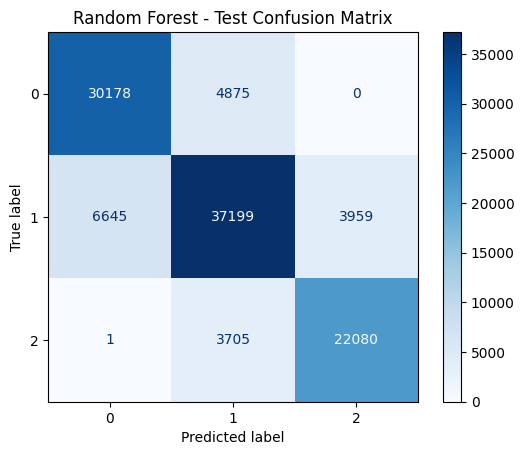

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)
import matplotlib.pyplot as plt

# Select the best model using validation Macro F1
best_model_name = comparison_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best model:", best_model_name)

# Predict on the unseen test set
y_test_pred = best_model.predict(X_test)

# Calculate evaluation metrics
print("\nTest Accuracy:",
      round(accuracy_score(y_test, y_test_pred), 4))

print("Test Balanced Accuracy:",
      round(balanced_accuracy_score(y_test, y_test_pred), 4))

print("Test Macro F1:",
      round(f1_score(y_test, y_test_pred, average="macro"), 4))

print("Test Weighted F1:",
      round(f1_score(y_test, y_test_pred, average="weighted"), 4))

# Detailed class-wise evaluation
print("\nClassification Report:")
print(classification_report(y_test, y_test_pred, labels=[0, 1, 2]))

# Confusion matrix
cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1, 2])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1, 2]
)

disp.plot(cmap="Blues", values_format="d")
plt.title(f"{best_model_name} - Test Confusion Matrix")
plt.show()

Top 15 Important Features:


,Feature,Importance
11,num__soil_ph,0.201345
25,cat__moisture_regime_optimal,0.114247
26,cat__moisture_regime_waterlogged,0.069365
5,num__soil_moisture_pct,0.055338
12,num__nitrogen_ppm,0.052928
8,num__soil_temp_c,0.052867
30,cat__nutrient_balance_deficient,0.044841
29,cat__thermal_regime_optimal,0.044519
32,cat__nutrient_balance_optimal,0.044132
9,num__air_temp_c,0.038898


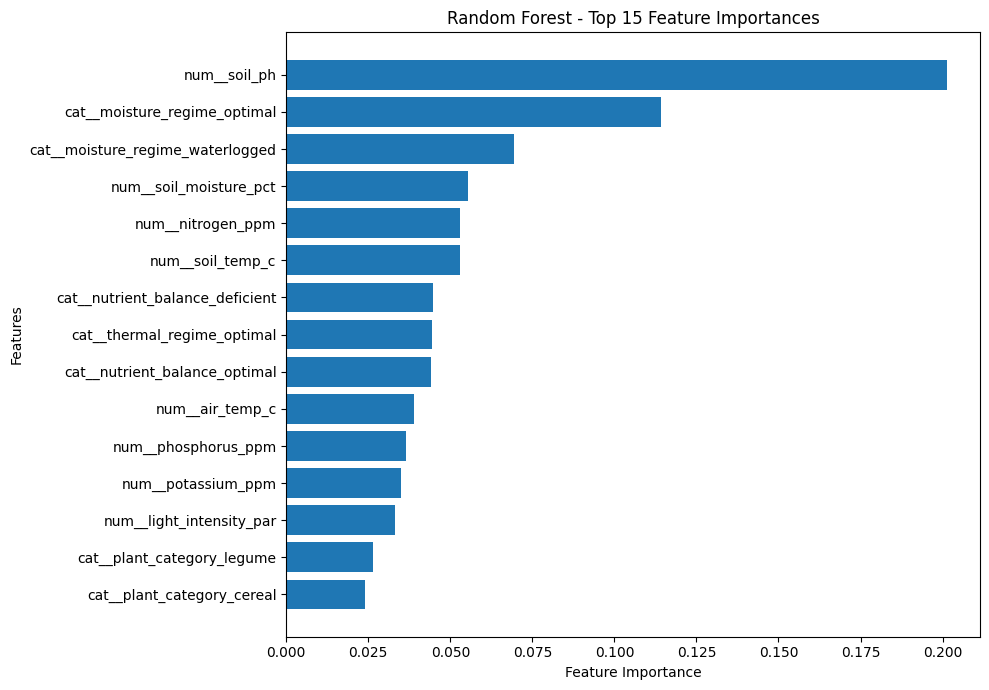

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Get the trained Random Forest classifier
rf_model = trained_models["Random Forest"]

# Get transformed feature names after preprocessing
feature_names = rf_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get feature importance values
importances = rf_model.named_steps[
    "classifier"
].feature_importances_

# Create a feature importance DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(
    by="Importance",
    ascending=False
)

# Display the top 15 features
print("Top 15 Important Features:")
display(feature_importance_df.head(15))

# Plot the top 15 features
top_features = feature_importance_df.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Random Forest - Top 15 Feature Importances")
plt.tight_layout()
plt.show()

In [ ]:
import os
import json
import joblib

# Create folder for model artifacts
os.makedirs("model4_artifacts", exist_ok=True)

# 1. Save the complete trained pipeline
joblib.dump(
    trained_models["Random Forest"],
    "model4_artifacts/model4_crop_stress.joblib"
)

# 2. Save test evaluation metrics
metrics = {
    "model": "Random Forest",
    "test_accuracy": float(accuracy_score(y_test, y_test_pred)),
    "test_balanced_accuracy": float(
        balanced_accuracy_score(y_test, y_test_pred)
    ),
    "test_macro_f1": float(
        f1_score(y_test, y_test_pred, average="macro")
    ),
    "test_weighted_f1": float(
        f1_score(y_test, y_test_pred, average="weighted")
    ),
    "target_column": "stress_level",
    "target_label_meanings_verified": False
}

with open("model4_artifacts/evaluation_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

# 3. Save feature importance
feature_importance_df.to_csv(
    "model4_artifacts/feature_importance.csv",
    index=False
)

# 4. Save model comparison
comparison_df.to_csv(
    "model4_artifacts/model_comparison.csv",
    index=False
)

# 5. Display saved files
print("Saved artifacts:")
for filename in os.listdir("model4_artifacts"):
    print(filename)

Saved artifacts:
evaluation_metrics.json
model_comparison.csv
feature_importance.csv
model4_crop_stress.joblib


In [ ]:
import numpy as np

# Load the saved pipeline
loaded_model = joblib.load(
    "model4_artifacts/model4_crop_stress.joblib"
)

# Select one test sample
sample = X_test.iloc[[0]]

# Predict stress class
prediction = loaded_model.predict(sample)[0]

# Get probabilities for each class
probabilities = loaded_model.predict_proba(sample)[0]
classes = loaded_model.named_steps["classifier"].classes_

print("Predicted stress_level:", prediction)
print("\nClass probabilities:")

for class_label, probability in zip(classes, probabilities):
    print(f"Class {class_label}: {probability:.4f}")

print("\nActual stress_level:", y_test.iloc[0])

Predicted stress_level: 2

Class probabilities:
Class 0: 0.0000
Class 1: 0.4613
Class 2: 0.5387

Actual stress_level: 2


In [ ]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "model4_artifacts",
    "zip",
    root_dir="model4_artifacts"
)

print("ZIP created successfully:", zip_path)

files.download(zip_path)

ZIP created successfully: /content/model4_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>